# Phase 1: Data Exploration
**SWE485 – Team Project | SW485-Project-Group2**
**Project:** Predicting Data Scientist Job Change: An Executive Decision-Support System for HR Retention Planning

| Section | Owner |
|---------|-------|
| 1. Introduction & Problem Statement | Manar |
| 2. Dataset Selection & Justification | Manar |
| 3. Initial Data Inspection (inspection, statistics, missing values) | Noura |
| 4. Exploratory Data Analysis | Rana |
| 5. Preprocessing Pipeline (5.1 duplicates & missing values: Noura; 5.2 encoding, scaling, outliers, feature engineering, split: Tojan) | Noura, Tojan |
| 6. Preprocessed Dataset Ready for Modeling | Tojan |
| 7. Key Insights & Challenges | Noura (+ all) |

**Team rules:** drop `enrollee_id` · no mean/median/mode imputation before the train/test split (no leakage) · split before scaling/encoding/resampling.

## 1. Introduction & Problem Statement

### Introduction
Data scientists are among the most sought-after professionals today, and companies that depend on them compete hard to hire and keep them. Many organizations go a step further and train their own data scientists, investing recruitment effort, onboarding time, and course hours in every candidate. That investment only pays off if the candidate stays. When a trained employee leaves for another job, the company loses the money spent on them, has to hire and train a replacement from scratch, and sees ongoing projects slow down. For HR leaders, this makes staff turnover one of the hardest parts of workforce planning.

The difficulty is that HR usually finds out about a departure only after it has happened, when it is too late to respond. Yet the signs are often already in the data the company holds about its candidates: where they live, their education and work experience, the size and type of their current employer, how long since their last job change, and how many training hours they have completed. These factors are rarely examined together, and no single one of them tells HR who is likely to leave.

This project uses machine learning to turn that data into early, practical advice for HR executives. We build an executive decision-support system on the Kaggle *HR Analytics: Job Change of Data Scientists* dataset. In this first phase we explore and clean the data, study which factors are linked to wanting a new job, and train and compare supervised classification models. In the next phase, the system will be extended with clustering of candidate profiles, AI-generated executive briefings, and an interactive dashboard.

### Problem Statement
HR leaders have no early, data-driven signal of which candidates are likely to look for a new job. This project builds a supervised classifier that predicts, from a candidate's demographics, education, experience, and training history, whether the candidate is **looking for a job change (1)** or **not (0)**. The predictions advise HR managers which candidates to prioritize for retention, helping them reduce recruitment costs, improve training investment, and design targeted retention strategies.


## 2. Dataset Selection & Justification

### Dataset Goal & Source
- **Dataset:** HR Analytics: Job Change of Data Scientists (Kaggle)
- **URL:** https://www.kaggle.com/datasets/arashnic/hr-analytics-job-change-of-data-scientists
- **File used:** `aug_train.csv`, saved in this repository as `Dataset/raw_kaggle_data.csv`
- **Purpose:** The dataset was built to understand which factors lead a data scientist to leave their current job, so that a company that trains data scientists can predict who will look for a new job (binary classification: 0 = not looking, 1 = looking) and use this to reduce hiring and training costs and to plan its workforce.

### Justification
| Criterion | Why this dataset is suitable |
|-----------|------------------------------|
| **Relevance** | It was designed for the same question we ask (will a trained data scientist look for a job change?). Its features (education, relevant experience, years of experience, company size and type, years since last job change, training hours, city development index) are the factors HR would consider. |
| **Completeness** | 19,158 records and 14 columns (13 predictors plus the target; `enrollee_id` is only an identifier), which is enough data for training, tuning, and cross-validation. Some columns have missing values (up to 32.0% in `company_type` and 31.0% in `company_size`); the missingness is itself informative (Section 3.3), so it is handled and not simply discarded. |
| **Quality** | It is a structured tabular file with a clear binary target and a mix of categorical and numeric features. The target is imbalanced (24.94% looking vs 75.06% not looking), which is realistic for HR data and means models must be judged by more than accuracy. |


In [1]:
# Setup: shared imports for the whole notebook (keep imports here, not in later cells)
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

## 3. Initial Data Inspection
*Owner: Noura – data inspection, statistics and missing values.*

### 3.1 Data Inspection

Load the raw data, drop `enrollee_id`, convert `target` to int and show the first rows.

In [2]:
# Load data and drop ID
df = pd.read_csv("Dataset/raw_kaggle_data.csv")
df = df.drop(columns=["enrollee_id"])
df["target"] = df["target"].astype(int)
print(df.shape)
df.head()

(19158, 13)


,city,city_development_index,gender,relevent_experience,enrolled_university,education_level,major_discipline,experience,company_size,company_type,last_new_job,training_hours,target
0,city_103,0.920,Male,Has relevent experience,no_enrollment,Graduate,STEM,>20,NaN,NaN,1,36,1
1,city_40,0.776,Male,No relevent experience,no_enrollment,Graduate,STEM,15,50-99,Pvt Ltd,>4,47,0
2,city_21,0.624,NaN,No relevent experience,Full time course,Graduate,STEM,5,NaN,NaN,never,83,0
3,city_115,0.789,NaN,No relevent experience,NaN,Graduate,Business Degree,<1,NaN,Pvt Ltd,never,52,1
4,city_162,0.767,Male,Has relevent experience,no_enrollment,Masters,STEM,>20,50-99,Funded Startup,4,8,0


Summary table per column: type, unique values and missing values.

In [3]:
# Per-column summary table
pd.DataFrame({
    "dtype": df.dtypes.astype(str),
    "n_unique": df.nunique(),
    "n_missing": df.isna().sum(),
    "pct_missing": (df.isna().mean() * 100).round(2),
})

,dtype,n_unique,n_missing,pct_missing
city,str,123,0,0.00
city_development_index,float64,93,0,0.00
gender,str,3,4508,23.53
relevent_experience,str,2,0,0.00
enrolled_university,str,3,386,2.01
education_level,str,5,460,2.40
major_discipline,str,6,2813,14.68
experience,str,22,65,0.34
company_size,str,8,5938,30.99
company_type,str,6,6140,32.05


Data-quality checks: drop duplicates, count cities, list `company_size` labels.

In [4]:
# Duplicates, cities, labels
print("Duplicates:", df.duplicated().sum())
df = df.drop_duplicates().reset_index(drop=True)
print("Shape:", df.shape)
print("Cities:", df["city"].nunique())
print("company_size values:", sorted(df["company_size"].dropna().unique()))

Duplicates: 49
Shape: (19109, 13)
Cities: 123
company_size values: ['10/49', '100-500', '1000-4999', '10000+', '50-99', '500-999', '5000-9999', '<10']


### 3.2 Statistics

Descriptive statistics and skewness of the two numeric columns.

In [5]:
# Numeric statistics and skewness
num = ["city_development_index", "training_hours"]
display(df[num].describe())
df[num].skew()

,city_development_index,training_hours
count,19109.000000,19109.000000
mean,0.828697,65.442200
std,0.123401,60.098917
min,0.448000,1.000000
25%,0.740000,23.000000
50%,0.903000,47.000000
75%,0.920000,88.000000
max,0.949000,336.000000


city_development_index   -0.993066
training_hours            1.817132
dtype: float64

Target balance: count and % of each class, with a bar chart.

        count    pct
target              
0       14344  75.06
1        4765  24.94


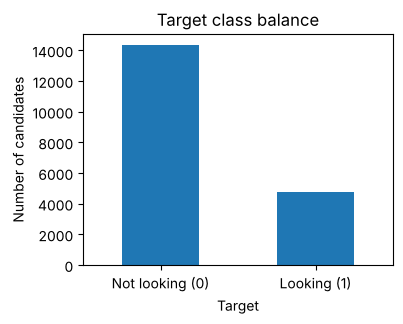

In [6]:
# Target balance and chart
counts = df["target"].value_counts()
print(pd.DataFrame({"count": counts, "pct": (counts / len(df) * 100).round(2)}))
ax = counts.plot(kind="bar", figsize=(4, 3))
ax.set_title("Target class balance")
ax.set_xlabel("Target")
ax.set_ylabel("Number of candidates")
ax.set_xticklabels([{0: "Not looking (0)", 1: "Looking (1)"}[i] for i in counts.index], rotation=0)
plt.show()

**Interpretation:** 75.06% are not looking (14,344) vs 24.94% looking for a job change (4,765), about 3:1, so accuracy alone would be misleading.

Job-change rate (%) per category for three columns, and by city development index band.

In [7]:
# Job-change rate per category
for col in ["relevent_experience", "experience", "company_type"]:
    rate = df.groupby(df[col].fillna("(missing)"))["target"].mean() * 100
    print(rate.round(1).sort_values(ascending=False))
    print()
band = pd.cut(df["city_development_index"], [0, 0.6, 0.7, 0.8, 0.9, 1.0])
(df.groupby(band, observed=True)["target"].mean() * 100).round(1)

relevent_experience
No relevent experience     33.8
Has relevent experience    21.5
Name: target, dtype: float64

experience
<1           45.3
1            42.4
(missing)    35.4
3            35.3
2            33.1
4            32.5
7            29.4
5            28.8
6            28.2
8            24.3
11           22.7
20           22.3
9            21.8
10           21.0
13           19.3
12           18.6
14           18.3
19           17.4
17           16.7
15           16.7
18           15.4
>20          15.3
16           14.2
Name: target, dtype: float64

company_type
(missing)              38.8
Other                  24.0
Early Stage Startup    23.5
Public Sector          22.0
NGO                    18.6
Pvt Ltd                18.1
Funded Startup         14.0
Name: target, dtype: float64



city_development_index
(0.0, 0.6]    57.9
(0.6, 0.7]    49.6
(0.7, 0.8]    24.7
(0.8, 0.9]    13.6
(0.9, 1.0]    16.8
Name: target, dtype: float64

### 3.3 Missing Values

Percentage of missing values per column, with a bar chart.

company_type           32.04
company_size           30.98
gender                 23.59
major_discipline       14.70
education_level         2.41
last_new_job            2.21
enrolled_university     2.02
experience              0.34
dtype: float64


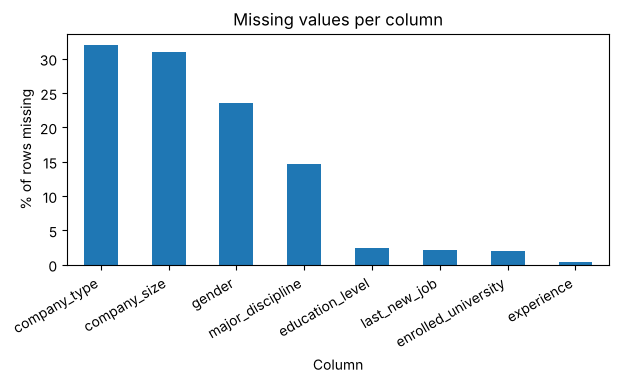

In [8]:
# Percent missing per column
miss = (df.isna().mean() * 100).round(2)
miss = miss[miss > 0].sort_values(ascending=False)
print(miss)
ax = miss.plot(kind="bar", figsize=(7, 3))
ax.set_title("Missing values per column")
ax.set_xlabel("Column")
ax.set_ylabel("% of rows missing")
plt.xticks(rotation=30, ha="right")
plt.show()

Job-change rate (%) when each column is missing vs present.

In [9]:
# Rate: missing vs present
pd.DataFrame({
    "rate_missing": [df.loc[df[c].isna(), "target"].mean() * 100 for c in miss.index],
    "rate_present": [df.loc[df[c].notna(), "target"].mean() * 100 for c in miss.index],
}, index=miss.index).round(1)

,rate_missing,rate_present
company_type,38.8,18.4
company_size,40.6,17.9
gender,30.8,23.1
major_discipline,19.5,25.9
education_level,22.6,25.0
last_new_job,36.4,24.7
enrolled_university,31.9,24.8
experience,35.4,24.9


**Interpretation:** when `company_type` is missing the job-change rate is 38.8% vs 18.4% when present (`company_size`: 40.6% vs 17.9%), so missingness is informative and is kept as `Unknown`.

## 4. Exploratory Data Analysis
*Owner: Rana – class distribution, feature distributions, relationships with the target, correlation heatmap, and an interpretation after every visualization.*

> **Note for Rana (delete when done):** use the dataframe `df` from Section 3 (raw data without `enrollee_id` and without duplicates; missing values still visible). Do **not** modify `df` in place; use `df.copy()` if you need to change anything. Noura already shows the target balance in 3.2, so link to it rather than repeating it.

## 5. Preprocessing Pipeline
*Every step needs a justification. Do not impute with the mean/median/mode before the train/test split.*

### 5.1 Duplicates & Missing Values
*Owner: Noura. Duplicates were already removed in Section 3.1 (49 rows).*

Apply the fixed cleaning rules, check that nothing is missing and save `Dataset/cleaned_data.csv`.

In [10]:
# Clean, verify and save
clean = df.copy()
clean["company_size"] = clean["company_size"].replace("10/49", "10-49")
school = clean["education_level"].isin(["Primary School", "High School"]) & clean["major_discipline"].isna()
clean.loc[school, "major_discipline"] = "No Major"
cols = ["company_type", "company_size", "gender", "major_discipline", "enrolled_university", "education_level"]
clean[cols] = clean[cols].fillna("Unknown")
clean = clean.dropna(subset=["experience", "last_new_job"]).reset_index(drop=True)
print("Missing left:", clean.isna().sum().sum())
print("Shape:", clean.shape)
clean.to_csv("Dataset/cleaned_data.csv", index=False)

Missing left: 0
Shape: (18645, 13)


**Interpretation:** 0 missing values are left and the cleaned data has 18,645 rows × 13 columns (97.3% of the 19,158 raw rows).

### 5.2 Encoding, Scaling, Outliers, Feature Engineering & Train/Test Split
*Owner: Tojan.*

> **Note for Tojan (delete when done):** continue from the dataframe `clean` above (also saved as `Dataset/cleaned_data.csv`); `target` is already int 0/1; ordinal columns (`experience`, `last_new_job`, `company_size`, `education_level`) need an ordered mapping; `city` duplicates `city_development_index`, so one of them is enough. **Split first (stratified, `random_state=42`), then fit the encoders/scalers on the training set only.** Decide and justify how to handle class imbalance (e.g. class weights).

## 6. Preprocessed Dataset Ready for Modeling
*Owner: Tojan – show the final dataset's shape and a preview, and save it as `Dataset/preprocessed_data.csv`.*

## 7. Key Insights & Challenges

*Owner: Noura – insights from inspection and missing values. Rana and Tojan add their own findings below.*

### Key Insights
- **Imbalanced target:** 24.9% are looking for a job change vs 75.1% not looking (about 3:1).
- **City development is the strongest signal:** job-change rate is 57.9% when CDI ≤ 0.6 vs 13.6–16.8% when CDI > 0.8. CDI is skewed left (−0.99), training_hours skewed right (1.82).
- **Less experience means more likely to look for a job change:** 45.3% for <1 year vs 15.3% for >20 years; 33.8% with no relevant experience vs 21.5% with it.
- **Missing values are informative:** company_type (32.0%) and company_size (31.0%) are missing most, and 38.8% and 40.6% of those rows are looking for a job change vs about 18% when present, so they were filled with 'Unknown' instead of dropped or mode-filled.
- **Clean result:** 19,158 raw rows → 18,645 rows × 13 columns with 0 missing (49 duplicates and 464 rows missing experience/last_new_job dropped).

**For Tojan (preprocessing):** use `Dataset/cleaned_data.csv`; `target` is already int 0/1; ordinal columns (experience, last_new_job, company_size, education_level) need an ordered mapping; `city` duplicates `city_development_index`, so one of them is enough.


### EDA insights and challenges (Rana)
*To be added.*

### Preprocessing insights and challenges (Tojan)
*To be added.*